# Autoencoders for Galaxy Images

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 15 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://statml.org/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

A survey takes images of more galaxies than we can inspect, and each image has thousands of pixels. In Tutorial 10 we reduced such images with principal component analysis (PCA, Chapter 10). PCA rebuilds each image from a few components. It assumes that an image is a linear combination of them, so it can miss subtle structure (Section 15.10). Because galaxies have different orientations, elongation can spread over several components (Section 10.9).

An autoencoder (Section 15.10) keeps the aim of PCA, a short code that rebuilds the image with a small error. It replaces the linear maps by two neural networks. The encoder $e(\mathbf{x})$ maps an image $\mathbf{x}$ to a latent vector $\mathbf{z}$, which is the short code. The decoder $d(\mathbf{z})$ rebuilds the image from $\mathbf{z}$. The bottleneck of a few numbers makes the network keep the structure that the reconstruction needs. We train both networks together to minimize the reconstruction error.

A network with many weights can memorize a small sample (Section 15.3). We therefore keep validation images to monitor the training and test images to score the result.

In this tutorial we train an autoencoder with 32 latent values on the galaxy images of Tutorial 10. We first ask whether its nonlinear code keeps structure that PCA with 32 components misses, and we look at test galaxies for this. We then probe the latent space by decoding single latent values and by interpolating between two galaxies. Finally we use the reconstruction error to find unusual galaxies.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Neural networks, with fully connected layers, activation functions, backpropagation and autoencoders (Chapter 15)
- Basic PyTorch, with tensors, modules and a training loop (Tutorial 15a)
- Principal component analysis and the singular value decomposition (Chapter 10)
- Training, validation and test sets (Chapter 4)

### Learning Objectives

After this tutorial you can do the following.

- Build an autoencoder in PyTorch with an encoder, a decoder and a bottleneck
- Train it with mini-batches and use early stopping on the validation loss
- Recognize overfitting from the losses and from the reconstructions of training and validation images
- Compare its reconstructions with those of PCA on test images
- Probe the latent space by decoding single latent values and by interpolating between two images
- Use the reconstruction error to find unusual images

We begin by importing the libraries and setting the plot style.

In [1]:
# Import the libraries
import copy
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Color maps of the book, white to a palette color to its dark shade, and blue-white-red
book_maps = [('book_blue', 'w', 'C0', '#172F4C'), ('book_green', 'w', 'C2', '#153F32'),
             ('book_orange', 'w', 'C1', '#724D1D'), ('book_div', 'C0', 'w', 'C3'),
             ('book_grey', 'w', '#9E9E9E', '#222222')]
for name, *colors in book_maps:
    plt.colormaps.register(LinearSegmentedColormap.from_list(name, colors), force=True)

# Set the random seed of PyTorch for reproducibility
_ = torch.manual_seed(42)

# Use a GPU when one is available, and the CPU otherwise
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

%matplotlib inline

## The Galaxy Images

We use the galaxy images of Tutorial 10. They are cutouts from the SDSS images of Galaxy Zoo 2, as in [Ma et al. 2026](https://ui.adsabs.harvard.edu/abs/2026ApJS..282...25M/abstract). We subsample each image to 64 × 64 pixels with values between 0 and 1. Each galaxy is therefore a point in a space of 4,096 dimensions. We load the images and print their shape and pixel values.

In [2]:
# Load the galaxy images, one row for each galaxy
galaxy_images = np.load('../data/dataset_images_galaxy.npy')

# Print the shape (galaxies, pixels) and the pixel value statistics
print("Shape of the galaxy images =", galaxy_images.shape)
print(f"Pixel values: minimum = {np.min(galaxy_images):.3f}, maximum = {np.max(galaxy_images):.3f}, "
      f"mean = {np.mean(galaxy_images):.3f}")

Shape of the galaxy images = (1500, 4096)
Pixel values: minimum = 0.000, maximum = 0.899, mean = 0.065


We show eight galaxies in a grid. Each tile has its own brightness scale.

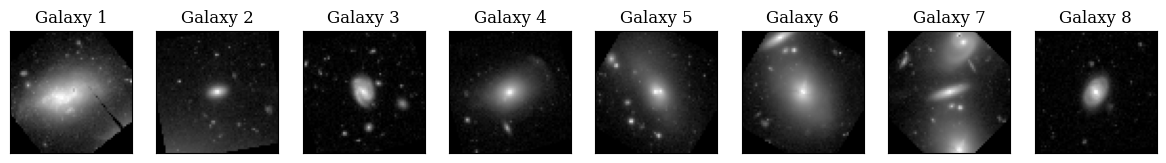

In [3]:
def plot_gallery(images, titles, h, w, n_row=2, n_col=6):
    """Plot the rows of `images` as h x w images in an n_row x n_col grid."""

    # Check that there are enough images and titles for the grid
    assert len(images) >= n_row * n_col
    assert len(titles) >= n_row * n_col

    # Set up the figure, 11.7 inches wide like the other figures
    tile = 11.7 / n_col
    plt.figure(figsize=(11.7, 4 / 3 * tile * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)

    # Loop to populate the gallery
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)

        # Reshape the flattened image to 2D and plot it
        plt.imshow(images[i].reshape((h, w)), cmap=plt.cm.gray)

        # Add the title and remove the axis ticks
        plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())

    plt.show()

# Show the first eight galaxies
plot_gallery(galaxy_images, [f"Galaxy {i + 1}" for i in range(8)], 64, 64, 1, 8)

The galaxies differ in size, shape and brightness. Some cutouts hold bright neighbors, and some have black corners from the edge of the image frame.

## The Autoencoder Architecture

We have 1,500 images of 4,096 pixels each, and we want a code of 32 numbers for each of them. PCA describes the variation of the images with linear combinations of the pixel values. An autoencoder can learn nonlinear transformations instead.

### Mathematical Formulation

We follow the notation of Chapter 15. The encoder $e(\mathbf{x})$ maps an image $\mathbf{x} \in \mathbb{R}^{D}$ to a latent vector $\mathbf{z} \in \mathbb{R}^{M}$. The decoder $d(\mathbf{z})$ maps $\mathbf{z}$ back to $\mathbb{R}^{D}$. Here $D = 4096$ is the number of pixels and $M = 32$ is the number of latent dimensions. The reconstruction of an image is

$$\hat{\mathbf{x}} = d(e(\mathbf{x})).$$

We minimize the mean squared error (MSE) between the input and its reconstruction,

$$\mathcal{L} = \frac{1}{ND}\sum_{i=1}^{N}\|\mathbf{x}_i - d(e(\mathbf{x}_i))\|^2,$$

where $N$ is the number of images. This is the loss of Section 15.10 divided by $D$, which is what `nn.MSELoss` computes.

### Network Design

Our architecture is symmetric. The encoder narrows the image from 4,096 values to 512, 128 and 32 values, and the decoder widens the code again. The bottleneck is the constraint that drives the learning. Without it the network could copy the input to the output (Section 15.10).

Each hidden layer applies a linear map followed by an activation function (Section 15.5). We use the GELU, a smooth variant of the ReLU, as in Tutorial 15a. Without the activations both networks would be linear, and the autoencoder would be equivalent to PCA (Section 15.10). The latent vector passes through a ReLU, so its values are not negative. The output of the decoder is a linear map without activation, so the reconstructed pixels can take any value.

We choose $M = 32$ latent dimensions, so 4,096 pixel values become 32 numbers, a compression of 128 to 1. Tutorial 10 found that 23 components keep 80 percent of the variance of these galaxies, so 32 is a little more.

We now define the network as a PyTorch module and count its parameters. The class `nn.Sequential` applies its layers in order.

In [4]:
class AutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder e(x)
        self.encoder = nn.Sequential(
            nn.Linear(4096, 512),   # Layer 1, compress the image
            nn.GELU(),              # Nonlinear activation
            nn.Linear(512, 128),    # Layer 2, compress further
            nn.GELU(),
            nn.Linear(128, 32),     # Layer 3, final compression to the latent space
            nn.ReLU()               # The latent values are non-negative
        )

        # Decoder d(z)
        self.decoder = nn.Sequential(
            nn.Linear(32, 128),     # Layer 1, begin the expansion from the latent space
            nn.GELU(),
            nn.Linear(128, 512),    # Layer 2, continue the expansion
            nn.GELU(),
            nn.Linear(512, 4096)    # Layer 3, rebuild the original image dimensions
        )

    def forward(self, x):
        z = self.encoder(x)         # Encode, z = e(x)
        x_hat = self.decoder(z)     # Decode, x_hat = d(z)
        return x_hat

# Instantiate the model and move it to the device
model = AutoEncoder().to(device)

# Count the parameters
total_params = sum(p.numel() for p in model.parameters())
encoder_params = sum(p.numel() for p in model.encoder.parameters())
decoder_params = sum(p.numel() for p in model.decoder.parameters())
print(f"Parameters = {total_params:,} (encoder {encoder_params:,}, decoder {decoder_params:,})")

Parameters = 4,338,976 (encoder 2,167,456, decoder 2,171,520)


## Training the Autoencoder

PCA has a closed-form solution through the eigendecomposition (Chapter 10). An autoencoder needs iterative optimization with gradient descent, which takes more computing time. We first split the images, and we then choose the optimizer.

### Data Preparation and Splits

A network with many parameters can overfit. It then memorizes the training images and learns features that do not generalize (Section 15.3). We split the 1,500 galaxy images at random into 60 percent training images, 20 percent validation images and 20 percent test images (Section 4.7). This gives 900, 300 and 300 images. Our network has 4.3 million parameters, and the 900 training images have 3.7 million pixel values.

The split has two steps. The first sets aside 20 percent test images. The second divides the remaining 80 percent into 75 percent training images and 25 percent validation images, so that the three sets have different roles.

- The training images update the weights, and the network learns from them only.
- The validation images monitor the overfitting and choose the epoch whose weights we keep. The network never updates on them, but our choice depends on them.
- The test images take no part in the training or in any choice, so they show how the final network does on new images.

We use the pixel values as they are, so no statistic of the test images enters the preparation.

We train with mini-batches (Section 15.3). They reduce the cost of an update, and their noise can help the optimization to escape shallow minima. We use 60 images in a batch, so the training images make 15 equal batches. One epoch is one pass through all training images, which is 15 updates. A `DataLoader` splits the training images into mini-batches and shuffles them in each epoch, as in Tutorial 15a.

In [5]:
# First split, into 80 percent remaining and 20 percent test images
rng = np.random.default_rng(42)
order = rng.permutation(len(galaxy_images))
n_remaining = int(0.8 * len(galaxy_images))
remaining_index, test_index = order[:n_remaining], order[n_remaining:]

# Second split, of the remaining images into 75 percent training and 25 percent validation images
n_train = int(0.75 * n_remaining)
train_index, val_index = remaining_index[:n_train], remaining_index[n_train:]

# Convert each set to a tensor on the device
x_train, x_val, x_test = [torch.tensor(galaxy_images[index], dtype=torch.float32).to(device)
                        for index in (train_index, val_index, test_index)]

# Mini-batches of the training images, drawn in a new random order in each epoch
batch_size = 60
train_loader = DataLoader(TensorDataset(x_train), batch_size=batch_size, shuffle=True)
print(f"Training {len(x_train)}, validation {len(x_val)}, test {len(x_test)} images, "
      f"{len(train_loader)} batches per epoch")

Training 900, validation 300, test 300 images, 15 batches per epoch


### Optimization Strategy

The split fixes which images the network sees, and the optimizer decides how it learns from them. We use the Adam optimizer of Tutorial 15a (Section 15.3). It rescales the step of each parameter by the size of its recent gradients. The learning rate starts at 0.001 and falls to zero along a cosine curve over 200 epochs (Tutorial 15a). A high rate at the start trains fast, and a low rate at the end lets the loss settle.

Each epoch has four steps.

1. Update the weights once for each of the 15 mini-batches of training images.
2. Lower the learning rate by one step along the cosine curve.
3. Compute the MSE of all training images and of all validation images for the same weights. The losses of the mini-batches are not enough, because the weights change during the epoch.
4. Keep a copy of the weights if the validation loss is the lowest so far.

The fourth step is early stopping (Section 15.3), except that we always train all 200 epochs. We also keep the reconstructions of four training images and four validation images at the epochs 1, 5, 20, 75 and 200.

In [6]:
# Training configuration
learning_rate = 1e-3
n_epochs = 200
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
loss_function = nn.MSELoss()

# The scheduler lowers the learning rate along a cosine curve over the epochs
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

# Epochs at which we keep reconstructions of four training and four validation images
snapshot_epochs = [1, 5, 20, 75, 200]
snapshots = {}

# Lists for the losses, and the lowest validation loss so far
train_losses = []
val_losses = []
best_val_loss = float('inf')

for epoch in range(n_epochs):
    # Training phase, one update for each mini-batch
    model.train()  # Training mode
    for (x,) in train_loader:
        loss = loss_function(model(x), x)
        optimizer.zero_grad()   # Reset the gradients
        loss.backward()         # Backpropagate the loss
        optimizer.step()        # Update the weights

    scheduler.step()        # Lower the learning rate along the cosine curve

    # Evaluate all training and validation images with the same weights, without gradients
    model.eval()  # Evaluation mode
    with torch.no_grad():
        train_losses.append(loss_function(model(x_train), x_train).item())
        val_losses.append(loss_function(model(x_val), x_val).item())

        # Keep the reconstructions of the first four training and validation images
        if epoch + 1 in snapshot_epochs:
            snapshots[epoch + 1] = (model(x_train[:4]).cpu().numpy(), model(x_val[:4]).cpu().numpy())

    # Save a copy of the weights with the lowest validation loss
    # A deep copy is needed, because state_dict() returns the live weights
    if val_losses[-1] < best_val_loss:
        best_val_loss = val_losses[-1]
        best_state = copy.deepcopy(model.state_dict())

We plot the training loss and the validation loss against the epoch. A dashed line marks the epoch with the lowest validation loss. The first epochs lie above the top of the plot.

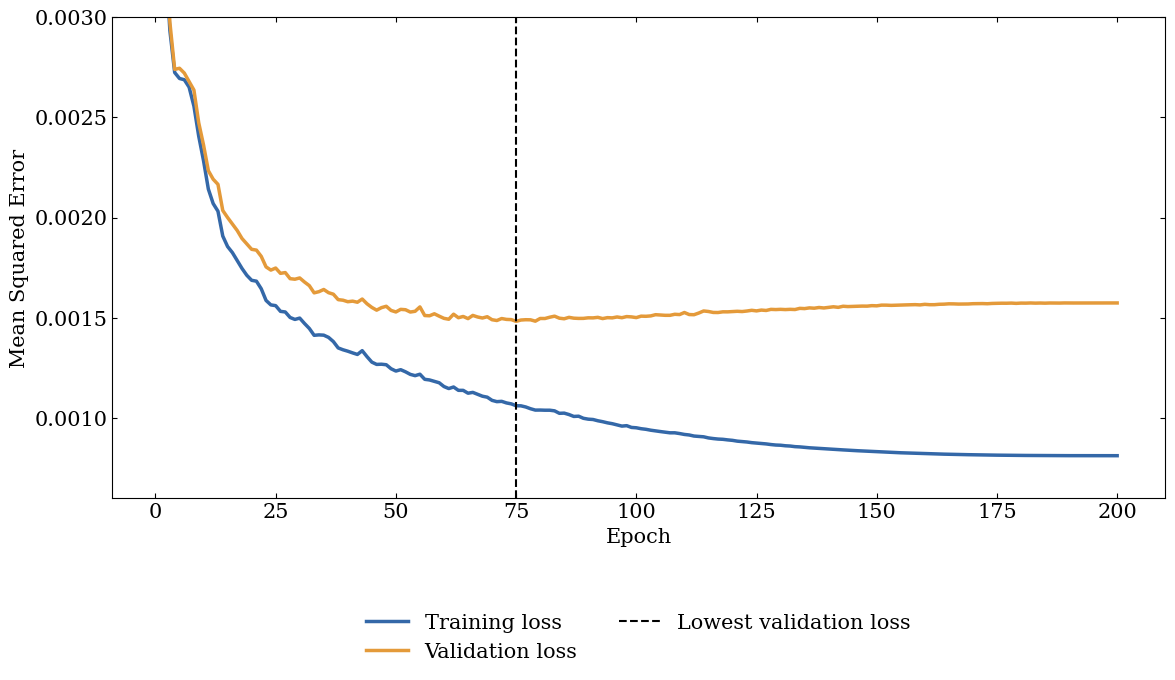

Lowest validation loss = 0.001482 at epoch 75
Final training loss = 0.000812, validation loss = 0.001574


In [7]:
# Plot the losses, with the epochs counted from 1
epochs = np.arange(1, n_epochs + 1)
best_epoch = int(np.argmin(val_losses)) + 1
plt.figure(figsize=(12.0, 7.2))
plt.plot(epochs, train_losses, label='Training loss', linewidth=2.5, color='C0')
plt.plot(epochs, val_losses, label='Validation loss', linewidth=2.5, color='C1')
plt.axvline(best_epoch, color='k', linestyle='--', linewidth=1.5, label='Lowest validation loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.ylim(0.0006, 0.003)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.show()

# Print the lowest validation loss and the final losses
print(f"Lowest validation loss = {best_val_loss:.6f} at epoch {best_epoch}")
print(f"Final training loss = {train_losses[-1]:.6f}, validation loss = {val_losses[-1]:.6f}")

Both losses fall quickly in the first epochs, and the training loss keeps falling. The validation loss reaches its lowest value at epoch 75 and then rises slowly. The gap between the two losses grows because the network fits the training images better than new images, which is overfitting. Both curves flatten at the end, because the cosine curve brings the learning rate to zero. We keep the weights of epoch 75 and not those of epoch 200, which is early stopping (Section 15.3).

### Reconstructions During the Training

The losses are numbers. We now look at what they mean for the images. The figure shows four training images and four validation images. The top row holds the originals, and the rows below hold the reconstructions at the epochs that we kept. The network never updates on the validation images. We also print the loss of all training and all validation images at these epochs.

Epoch 1: training images 0.00429, validation images 0.00443
Epoch 5: training images 0.00269, validation images 0.00275
Epoch 20: training images 0.00169, validation images 0.00184
Epoch 75: training images 0.00106, validation images 0.00148
Epoch 200: training images 0.00081, validation images 0.00157


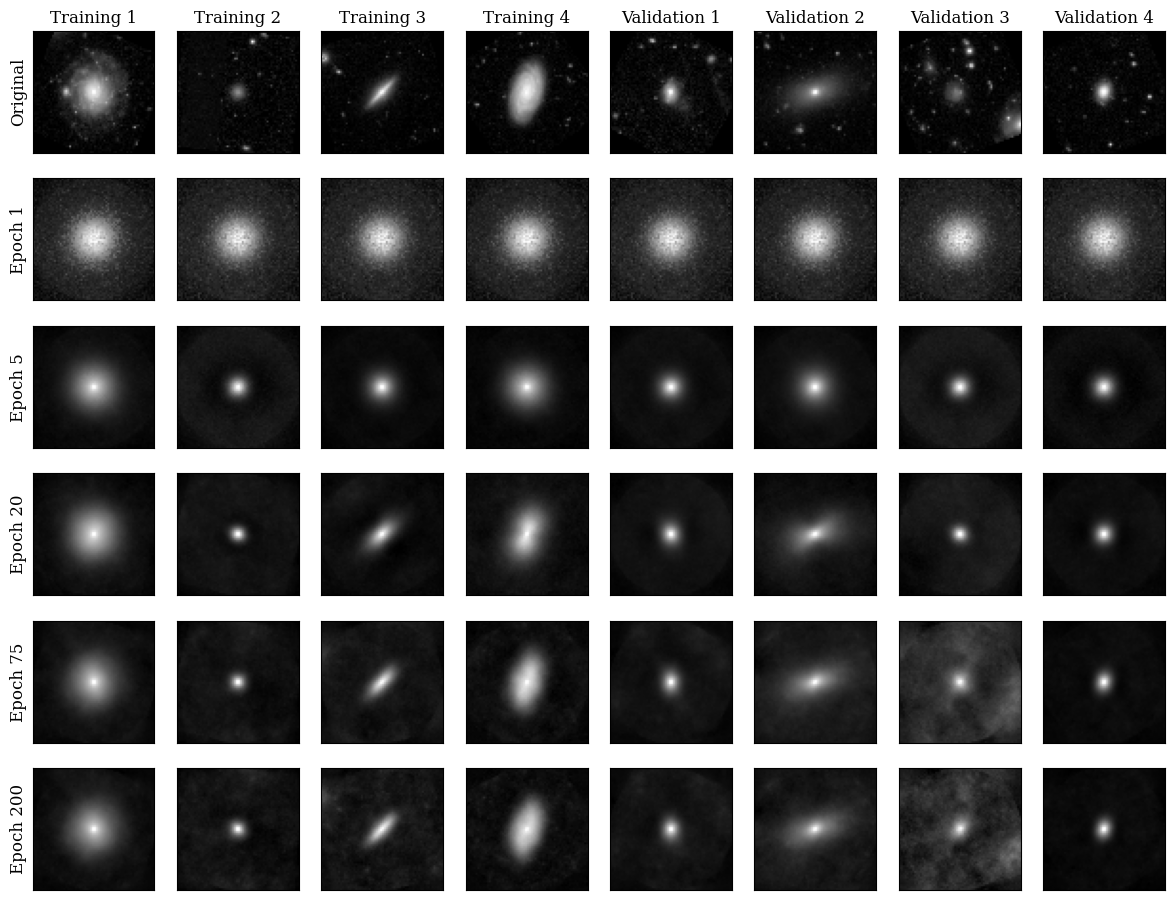

In [8]:
# The first four training and validation images, as arrays
originals = (x_train[:4].cpu().numpy(), x_val[:4].cpu().numpy())

# Print the training and validation loss of all images at each kept epoch
for epoch in snapshot_epochs:
    print(f"Epoch {epoch}: training images {train_losses[epoch - 1]:.5f}, "
          f"validation images {val_losses[epoch - 1]:.5f}")

# Rows, the originals and the kept epochs. Columns, four training images and four validation images
fig, axes = plt.subplots(6, 8, figsize=(12.0, 9.3))
for r in range(6):
    for c in range(8):
        part, k = divmod(c, 4)
        image = originals[part][k] if r == 0 else snapshots[snapshot_epochs[r - 1]][part][k]

        # Show the image without ticks
        axes[r, c].imshow(image.reshape(64, 64), cmap='gray')
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel('Original' if r == 0 else f'Epoch {snapshot_epochs[r - 1]}', fontsize=12)
for c in range(8):
    axes[0, c].set_title(f"{'Training' if c < 4 else 'Validation'} {c % 4 + 1}", fontsize=12)
plt.tight_layout()
plt.show()

At epoch 1 the output is noise around a blob. At epoch 5 it is a round source. At epoch 20 it has the elongation and the orientation of the galaxies, and at epoch 75 it is close to the final result. From epoch 75 to 200 the training loss falls and the validation loss rises. The training images gain faint specks in the background and near the edges. The network starts to store details of the training images, which is overfitting that we can now see.

## Reconstruction Quality

The training is done, and we keep the weights of the best epoch. We now compare the autoencoder with PCA on test images, to see whether its nonlinear code keeps structure that the linear PCA misses. PCA with 32 components is the baseline with the same number of latent values. In Tutorial 10 we fitted PCA to all galaxies and rebuilt the same galaxies. Here we fit PCA to the training images only, and we rebuild the test images as for the autoencoder.

We first restore the weights of the epoch with the lowest validation loss. We then reconstruct the test images.

In [9]:
# Restore the weights of the epoch with the lowest validation loss
model.load_state_dict(best_state)
model.eval()

# Reconstruct the test images
with torch.no_grad():
    test_ae = model(x_test).cpu().numpy()


We fit PCA to the training images with the SVD (Section 10.8), as in Tutorial 10. The fit has four steps.

1. Compute the mean image $\overline{\mathbf{x}}$ of the training images, and subtract it from every image. The rows of $\mathbf{X}$ are now the centered images.
2. Compute the SVD of the centered images, $\mathbf{X} = \mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^T$. The columns of $\mathbf{V}$ are the principal components, the directions in pixel space along which the images vary most.
3. Keep the first $M = 32$ columns of $\mathbf{V}$, which form the matrix $\mathbf{V}_M$.
4. Project an image onto these components, $\mathbf{z} = (\mathbf{x} - \overline{\mathbf{x}})\mathbf{V}_M$, and rebuild it from its 32 coefficients (Section 10.1),

$$\hat{\mathbf{x}} = \mathbf{z}\mathbf{V}_M^T + \overline{\mathbf{x}}.$$

The mean image and the components come from the training images only. We apply them unchanged to the test images, so no test image enters the fit. In the code, the rows of `Vt` are the columns of $\mathbf{V}$.


In [10]:
# Select the training images and the test images as arrays
train_np = galaxy_images[train_index]
test_np = galaxy_images[test_index]

# Fit PCA with 32 components to the training images only
mean_image = train_np.mean(axis=0)

# The rows of Vt are the principal components of the centered images
_, _, Vt = np.linalg.svd(train_np - mean_image, full_matrices=False)
components = Vt[:32]

# Project the images on the components and rebuild them
def pca_reconstruct(images):
    return mean_image + ((images - mean_image) @ components.T) @ components

test_pca = pca_reconstruct(test_np)

We show the first six test galaxies, their PCA reconstructions and their autoencoder reconstructions. Each tile has its own brightness scale.

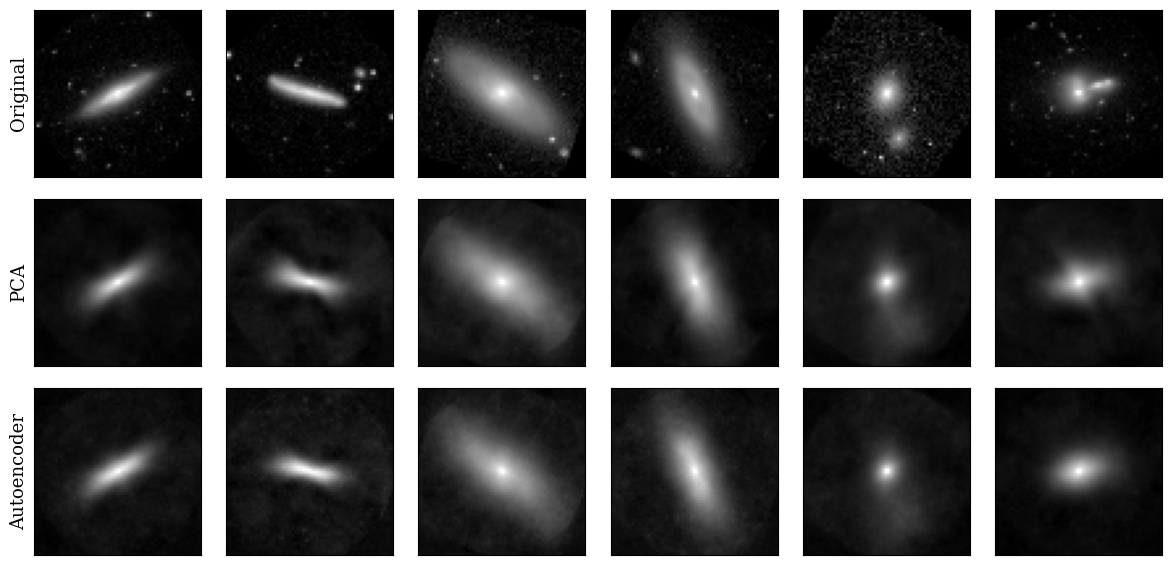

In [11]:
# Plot six test galaxies, their PCA reconstructions and their autoencoder reconstructions
fig, axes = plt.subplots(3, 6, figsize=(12.0, 5.9))
rows = [('Original', test_np), ('PCA', test_pca), ('Autoencoder', test_ae)]
for r, (name, images) in enumerate(rows):
    for c in range(6):
        axes[r, c].imshow(images[c].reshape(64, 64), cmap='gray')
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(name, fontsize=13)
plt.tight_layout()
plt.show()

Both methods keep the size, elongation and orientation of the main galaxy, and both drop the background noise. The autoencoder follows the structure more closely. Its thin disks are narrower and brighter than those of PCA, which spreads them out. The thin disk of the second galaxy becomes a bow tie in PCA and a bar in the autoencoder. The bow tie is the shape of the quadrupole eigengalaxies of Tutorial 10. In the last two galaxies PCA smears the light of a neighbor into the main galaxy, and the autoencoder keeps a compact core.

The autoencoder looks sharper in these six galaxies, but six are a small sample. We therefore measure the detail that each method keeps for all 300 test images. Both sets of reconstructions are smoother than the originals, because 32 numbers cannot hold the fine structure. We measure the sharpness of an image $I$ with its gradient magnitude at each pixel,

$$g = \sqrt{\left(\frac{\partial I}{\partial x}\right)^2 + \left(\frac{\partial I}{\partial y}\right)^2},$$

where the derivatives are the differences between neighboring pixels. The value $g$ is large at a sharp edge, where the brightness changes quickly from one pixel to the next. It is small in a smooth region. The sharpness of an image is the mean of $g$ over its pixels.

We compute the sharpness of every test image for the original, the PCA reconstruction and the autoencoder reconstruction. We print the mean over the test images for each of the three. We also count the test images for which the autoencoder is sharper than PCA.

In [12]:
# Mean gradient magnitude of each image, with the gradient in units of the pixel values per pixel
def gradient_magnitude(images):
    # The differences between neighboring pixels along y and along x
    gy, gx = np.gradient(images.reshape(-1, 64, 64), axis=(1, 2))

    # np.hypot(gy, gx) is sqrt(gy**2 + gx**2), the gradient magnitude g at each pixel
    # The mean over the rows and columns (axes 1 and 2) of each image is its sharpness
    return np.hypot(gy, gx).mean(axis=(1, 2))

# Sharpness of the originals, the PCA reconstructions and the autoencoder reconstructions
sharp_original = gradient_magnitude(test_np)
sharp_pca = gradient_magnitude(test_pca)
sharp_ae = gradient_magnitude(test_ae)
print(f"Mean gradient magnitude: original {sharp_original.mean():.4f}, "
      f"PCA {sharp_pca.mean():.4f}, autoencoder {sharp_ae.mean():.4f}")
print(f"The autoencoder is sharper than PCA for {np.sum(sharp_ae > sharp_pca)} of {len(test_np)} test images")

Mean gradient magnitude: original 0.0205, PCA 0.0106, autoencoder 0.0118
The autoencoder is sharper than PCA for 263 of 300 test images


The originals are the sharpest, because their fine structure and their noise give many sharp edges. Both reconstructions are about half as sharp, because they keep the large structure and drop most of the fine detail. The autoencoder is slightly sharper than PCA on average, and it is sharper for most of the test images. A larger sharpness means that a reconstruction keeps more detail.

## The Latent Space

The reconstructions show that the 32 numbers of the code hold the main structure of a galaxy. We now ask what these numbers mean. The latent dimensions of an autoencoder come from the optimization. We probe the code through the decoder in two ways. We first decode codes with a single non-zero value, and we then change single values in the code of a real galaxy.

### Decoding One Latent Value

To see what one latent dimension does, we decode a latent vector that has the value $s$ in dimension $k$ and zeros elsewhere (Section 15.10),

$$\mathbf{z}_k(s) = s\,\mathbf{e}_k = (0, \dots, 0, s, 0, \dots, 0), \qquad \hat{\mathbf{x}}_k(s) = d\left(\mathbf{z}_k(s)\right).$$

Here $\mathbf{e}_k$ is the unit vector with the value 1 in dimension $k$. The image $\hat{\mathbf{x}}_k(s)$ shows what dimension $k$ adds to the output of the decoder. We use the two scales $s = 1$ and $s = 10$ to see how the output changes when the value grows. The encoder ends with a ReLU, so the latent values are not negative, and we use $s > 0$. The cell decodes one vector for each of the 32 dimensions.

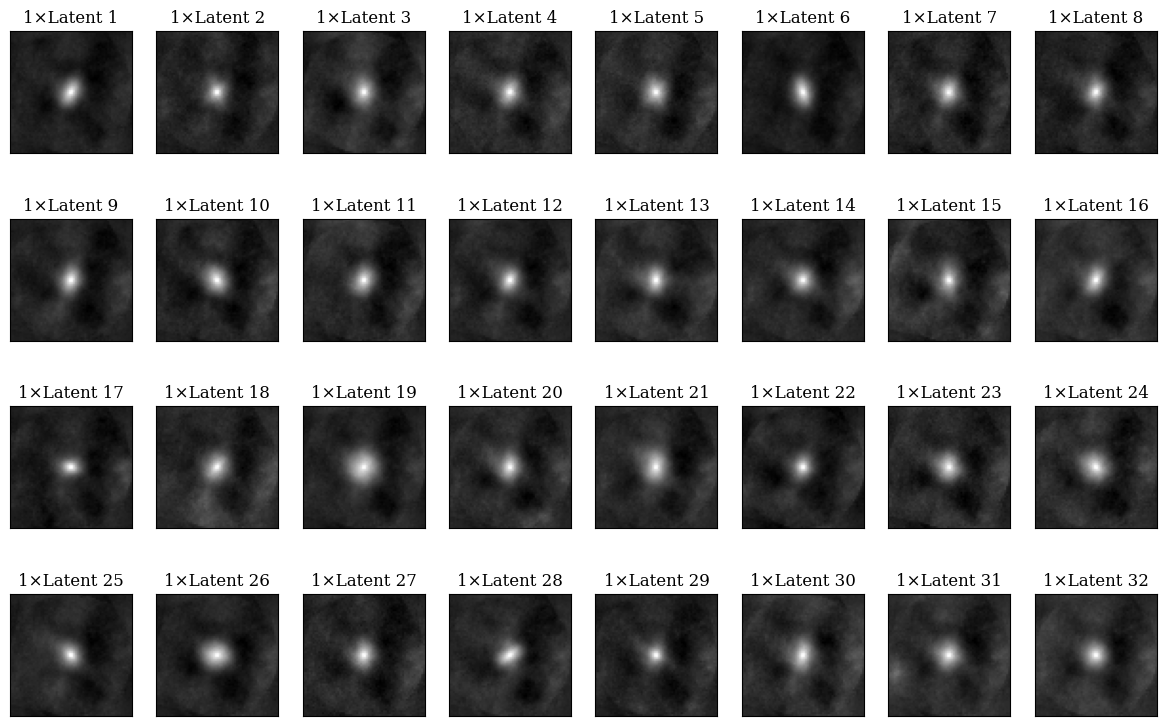

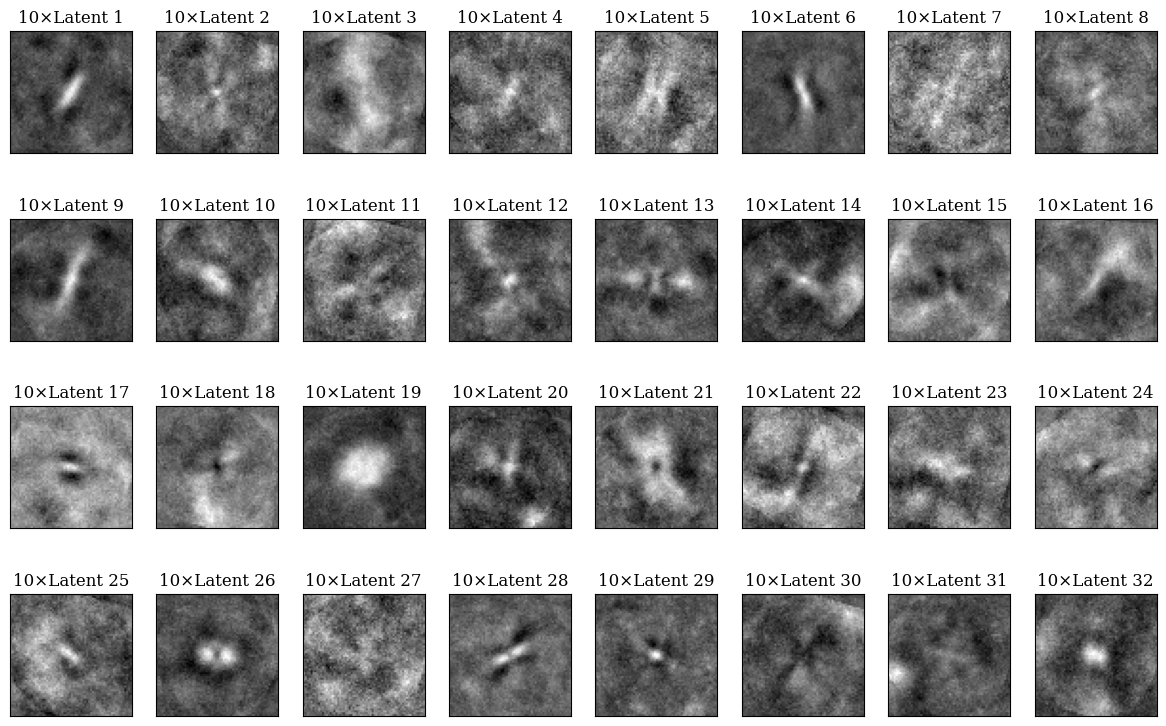

In [13]:
# Decode latent vectors that activate a single dimension, for two scales
for scale in [1, 10]:
    # The rows of the scaled identity matrix are the latent vectors
    latent_codes = scale * torch.eye(32).to(device)
    with torch.no_grad():
        decoded = model.decoder(latent_codes)

    # Show the decoded images
    plot_gallery(decoded.cpu().numpy(),
                 [f'{scale}×Latent {i + 1}' for i in range(32)],
                 64, 64, 4, 8)


The tiles show the decoder output for one latent dimension at a time. Different dimensions give different images. Some show elongated sources with different orientations, and others show rounder sources. The tiles at $s = 1$ show a compact source on a mottled background. The tiles at $s = 10$ show more structure, especially in the background.

A latent dimension comes from the optimization, so it need not match a physical property of a galaxy (Section 15.10).

### Scaling the Code of a Real Galaxy

The tiles above come from codes with one non-zero value, and a real galaxy has many non-zero values. We therefore start from the code $\mathbf{z} = e(\mathbf{x})$ of a real galaxy and change one value at a time. We take galaxy 151. The encoder turns it into a code of 32 numbers. We pick the two latent dimensions with the largest values, because a large value means that the dimension is active for this galaxy.

For a dimension $k$ and a scale $c$ we multiply the value $z_k$ by $c$ and keep the other 31 values,

$$\mathbf{z}'_k(c) = (z_1, \dots, c\,z_k, \dots, z_{32}), \qquad \hat{\mathbf{x}}_k(c) = d\left(\mathbf{z}'_k(c)\right).$$

We decode the changed codes for four scales. A title such as 2×Latent 1 means that $c = 2$ and $k = 1$.

- The scale $c = 0$ removes the dimension.
- The scale $c = 0.5$ halves it.
- The scale $c = 1$ leaves the code unchanged, so it gives the reconstruction $d(e(\mathbf{x}))$ of the galaxy.
- The scale $c = 2$ doubles it.

The first column of the figure shows the original galaxy, and each row follows one dimension.

Latent dimensions 1 and 16, with values 2.9 and 2.0


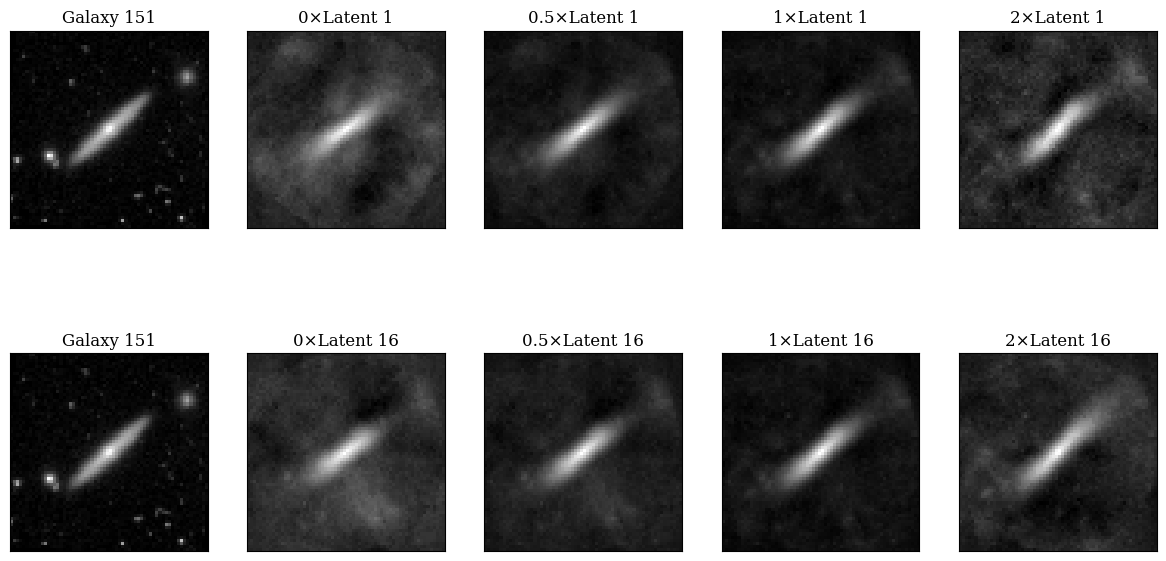

In [14]:
# Encode galaxy 151, the row 150 of the arrays, and find the two latent dimensions with the largest values
with torch.no_grad():
    z_galaxy = model.encoder(torch.tensor(galaxy_images[[150]], dtype=torch.float32).to(device))
largest = torch.argsort(z_galaxy[0], descending=True)[:2].tolist()
print("Latent dimensions " + " and ".join(str(d + 1) for d in largest) +
      ", with values " + " and ".join(f"{z_galaxy[0, d].item():.1f}" for d in largest))

# Decode the code with one value scaled by 0, 0.5, 1 and 2
tiles, tile_titles = [], []
for d in largest:
    for scale in (0, 0.5, 1, 2):
        z_scaled = z_galaxy.clone()
        z_scaled[0, d] *= scale
        with torch.no_grad():
            tiles.append(model.decoder(z_scaled).cpu().numpy()[0])
        tile_titles.append(f"{scale}×Latent {d + 1}")

# One row for each dimension, with the original galaxy in the first column
images = []
titles = []
for row in range(2):
    images += [galaxy_images[150]] + tiles[4 * row:4 * row + 4]
    titles += ["Galaxy 151"] + tile_titles[4 * row:4 * row + 4]
plot_gallery(images, titles, 64, 64, 2, 5)

Scaling one value changes the length, the width and the brightness of the galaxy, and the background level. The galaxy stays recognizable at every scale, because the other 31 values still describe it. The change is smoother than in the tiles above.

## Two Uses of the Learned Representation

Both uses treat the code as a description of a galaxy. We look at the interpolation between two galaxies and at the search for unusual galaxies.

### Interpolation in Latent Space

Scaling one value changes a galaxy in one direction. Interpolation instead moves the code from one galaxy to another and asks what lies between them. We encode two galaxies into the codes $\mathbf{z}_{51} = e(\mathbf{x}_{51})$ and $\mathbf{z}_{151} = e(\mathbf{x}_{151})$. Galaxy 51 is compact, and galaxy 151 is elongated.

We then take points on the straight line between the two codes and decode each of them,

$$\mathbf{z}(\alpha) = (1-\alpha)\,\mathbf{z}_{51} + \alpha\,\mathbf{z}_{151}, \qquad \hat{\mathbf{x}}(\alpha) = d\left(\mathbf{z}(\alpha)\right).$$

The number $\alpha$ runs from 0 at galaxy 51 to 1 at galaxy 151. The first and the last tile of the figure show the two original images. The six tiles in between show $\hat{\mathbf{x}}(\alpha)$ for six values of $\alpha$, which the titles give.

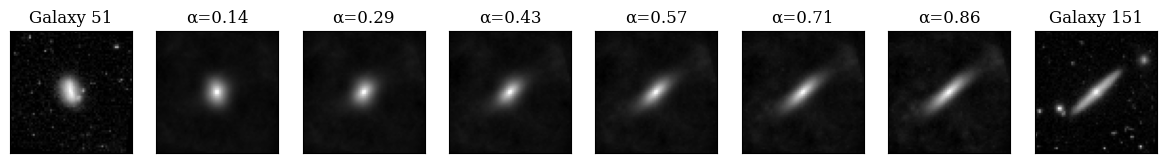

In [15]:
# Encode two galaxies with different morphologies, galaxies 51 and 151
idx1, idx2 = 50, 150
with torch.no_grad():
    z1 = model.encoder(torch.tensor(galaxy_images[[idx1]], dtype=torch.float32).to(device))
    z2 = model.encoder(torch.tensor(galaxy_images[[idx2]], dtype=torch.float32).to(device))

    # Decode six latent vectors on the line between them
    alphas = torch.linspace(0, 1, 8)[1:-1].reshape(-1, 1).to(device)
    interpolated = model.decoder((1 - alphas) * z1 + alphas * z2).cpu().numpy()

# Show the two galaxies at the ends and the decoded galaxies in between
images = np.vstack([galaxy_images[[idx1]], interpolated, galaxy_images[[idx2]]])
alpha_values = alphas.flatten().tolist()
titles = [f'Galaxy {idx1 + 1}'] + [f'α={a:.2f}' for a in alpha_values] + [f'Galaxy {idx2 + 1}']
plot_gallery(images, titles, 64, 64, 1, 8)

The decoded galaxy changes gradually from a round source to an elongated and tilted one. Nearby points on the line give similar galaxies, so the latent space is smooth between these two galaxies.

### Anomaly Detection Through Reconstruction Error

The second use looks at how well the network rebuilds a galaxy. The autoencoder learns from the training galaxies, so it learns to rebuild the typical ones. An image that differs from them is harder to rebuild, and its reconstruction error tends to be larger (Section 15.10). The error is therefore a score for how unusual an image is.

We score the 300 validation images and the 300 test images. We leave out the training images, because the network trained on them and rebuilds them better than new images. The error of an image is its MSE over the $D = 4096$ pixels, as in the loss,

$$E(\mathbf{x}) = \frac{1}{D}\left\|\mathbf{x} - d(e(\mathbf{x}))\right\|^2.$$

We compute $E$ for every scored image and print the median. We then pick the eight images with the largest $E$.

In [16]:
# Score the validation and test images, which the network did not train on
scored_images = galaxy_images[np.concatenate([val_index, test_index])]
scored_tensor = torch.tensor(scored_images, dtype=torch.float32).to(device)
with torch.no_grad():
    scored_reconstructed = model(scored_tensor).cpu().numpy()

# The reconstruction error of a galaxy is its mean squared error over the pixels
reconstruction_errors = np.mean((scored_reconstructed - scored_images) ** 2, axis=1)

print(f"Median error = {np.median(reconstruction_errors):.4f}")

# Find the galaxies with the 8 largest errors
anomaly_indices = np.argsort(reconstruction_errors)[-8:]

Median error = 0.0012


The figure shows the eight galaxies with the largest errors. Each column has the original image, its reconstruction and the absolute difference between them, where a dark pixel marks a large difference. The title gives the error.

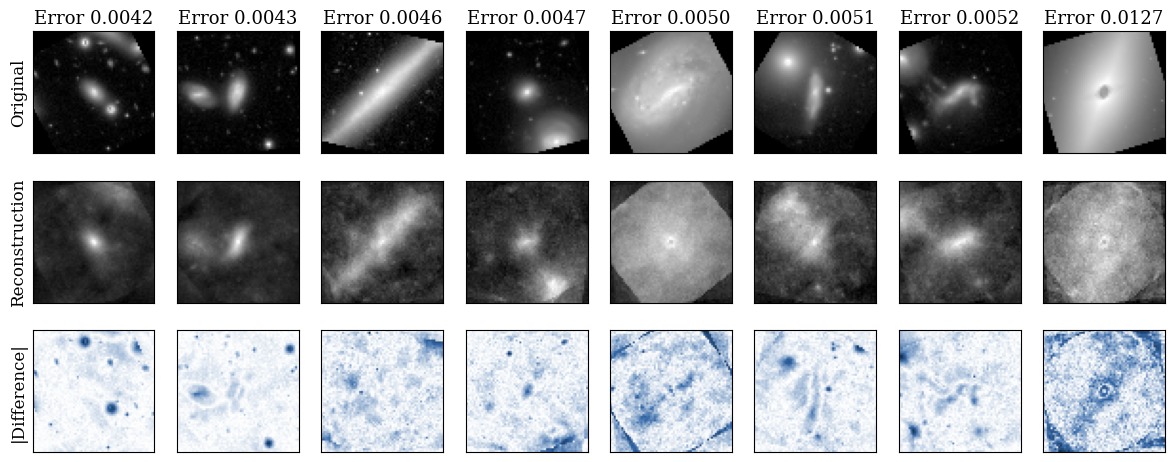

In [17]:
# Show the original, the reconstruction and the absolute difference of each galaxy
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for i, idx in enumerate(anomaly_indices):
    original = scored_images[idx].reshape(64, 64)
    reconstruction = scored_reconstructed[idx].reshape(64, 64)
    axes[0, i].imshow(original, cmap='gray')
    axes[0, i].set_title(f'Error {reconstruction_errors[idx]:.4f}', fontsize=13)
    axes[1, i].imshow(reconstruction, cmap='gray')
    axes[2, i].imshow(np.abs(original - reconstruction), cmap='book_blue')

# Remove the ticks and label the rows
for ax in axes.flatten():
    ax.set_xticks([])
    ax.set_yticks([])
for r, name in enumerate(['Original', 'Reconstruction', '|Difference|']):
    axes[r, 0].set_ylabel(name, fontsize=12)
plt.tight_layout()
plt.show()

The eight largest errors are several times the median error, and the largest is about ten times the median. In five of the eight images, two or more galaxies lie close together, and some show arcs. The reconstruction blurs or misses the fainter sources, and the difference maps show them as dark spots and arcs.

In two images a single large galaxy fills the cutout. In the eighth image a bright, smooth background fills the cutout, and the galaxy at the center is small. The tilted frame edges of three images give dark lines in the difference maps.

Whether such an image is of scientific interest depends on the application. A study of galaxy interactions looks for the pairs and the tidal arcs.

## Limits and Considerations

Our network has fully connected layers. They treat the pixels as an unordered list and ignore the grid of an image. A convolutional network applies the same small filters at every position. It finds a pattern wherever it appears and builds larger structures from local ones (Section 15.6). In principle it suits images better than our network, and a Transformer is another option (Section 15.6).

## Summary

In this tutorial we trained an autoencoder on galaxy images. Our main lessons follow.

1. **Nonlinear dimension reduction.** An autoencoder keeps the aim of PCA, a short code with a small reconstruction error. It replaces the linear maps by an encoder and a decoder. The bottleneck makes the network keep the structure that the reconstruction needs. Without activation functions the autoencoder would be equivalent to PCA.
2. **Architecture and training choices.** The architecture and the training settings shape what the network learns. The size of the bottleneck sets the compression, and the activation, the optimizer and the learning rate schedule affect how well the training works. Validation images are the right data to compare such choices.
3. **Overfitting and early stopping.** A network with many parameters can fit a small sample. The training loss then keeps falling while the validation loss stops falling, and the reconstructions of training images gain details that validation images do not. Early stopping keeps the weights with the lowest validation loss, and the test images show how the network does on new images.
4. **The latent space.** Decoding single latent values and scaling values in the code of a galaxy show what each dimension adds to the image. A latent dimension need not match a physical property.
5. **Interpolation.** The points on the line between two codes decode to galaxies that change shape gradually, so the latent space is smooth between them.
6. **Anomaly detection.** An autoencoder rebuilds what is typical in its training sample. An object that it rebuilds poorly differs from the sample, and what this means depends on the application.

An autoencoder learns a compact nonlinear representation of high-dimensional data from the data itself. Surveys deliver many high-dimensional images and spectra, and a learned representation helps us to compress, explore and screen them.